# Ablation Comparison (cross_day & cross_subject)

对比 4 组实验的 `cross_day` 和 `cross_subject` 结果（mean±sd，5 seeds）：
- **CNN-Full** — `result_day_td/`
- **CNN-Ablation** — `result_day_td_ablation/`
- **MLP-Full** — `results_mlp/`
- **MLP-Ablation** — `results_mlp_ablation/`

In [16]:
import os, re, glob
import numpy as np
import pandas as pd

EXPERIMENTS = {
    'CNN-Full':     '/root/zjm/cadt/result_day_td',
    'CNN-Ablation': '/root/zjm/cadt/result_day_td_ablation',
    'MLP-Full':     '/root/zjm/cadt/results_mlp',
    'MLP-Ablation': '/root/zjm/cadt/results_mlp_ablation',
}
SPLIT_MODES = ['cross_day', 'cross_subject']

OVERALL_METRICS = [
    ('Test MSE',              'Test MSE'),
    ('Test MAE',              'Test MAE'),
    ('Test RMSE',             'Test RMSE'),
    ('Test R2',               'Test R2'),
    ('Test Avg R2 (per-dim)', 'Test Avg R2'),
    ('Test Pearson',          'Test Pearson'),
    ('Test Spearman',         'Test Spearman'),
    ('Val MSE',               'Val MSE'),
    ('Val MAE',               'Val MAE'),
    ('Val RMSE',              'Val RMSE'),
    ('Val R2',                'Val R2'),
    ('Val Avg R2 (per-dim)',  'Val Avg R2'),
    ('Val Pearson',           'Val Pearson'),
    ('Val Spearman',          'Val Spearman'),
]

EMOTIONS = [
    'inspired', 'alert', 'determined', 'attentive', 'active',
    'hostile', 'nervous', 'upset', 'afraid', 'ashamed', 'fatigue'
]
PER_EMOTION_METRICS = ['MSE', 'MAE', 'R2', 'Pearson', 'Spearman']

print('Config loaded.')

Config loaded.


## 解析函数

In [17]:
def parse_results_txt(filepath):
    with open(filepath, 'r') as f:
        text = f.read()

    overall = {}
    for key in [m[0] for m in OVERALL_METRICS]:
        pattern = re.escape(key) + r":\s*([-+]?\d*\.?\d+)"
        m = re.search(pattern, text)
        if m:
            overall[key] = float(m.group(1))

    per_emotion_test, per_emotion_val = {}, {}

    test_section = re.search(
        r"--- Per-Emotion Metrics \(Test Set\) ---\s*\n.*?\n-+\n(.*?)(?:\n---|\Z)", text, re.DOTALL
    )
    if test_section:
        for emo in EMOTIONS:
            pattern = rf"^{emo}\s+([\d.]+)\s+([\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)"
            m = re.search(pattern, test_section.group(1), re.MULTILINE)
            if m:
                per_emotion_test[emo] = {
                    'MSE': float(m.group(1)), 'MAE': float(m.group(2)),
                    'R2': float(m.group(3)), 'Pearson': float(m.group(4)), 'Spearman': float(m.group(5)),
                }

    val_section = re.search(
        r"--- Per-Emotion Metrics \(Validation Set\) ---\s*\n.*?\n-+\n(.*?)(?:\n---|\Z)", text, re.DOTALL
    )
    if val_section:
        for emo in EMOTIONS:
            pattern = rf"^{emo}\s+([\d.]+)\s+([\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)"
            m = re.search(pattern, val_section.group(1), re.MULTILINE)
            if m:
                per_emotion_val[emo] = {
                    'MSE': float(m.group(1)), 'MAE': float(m.group(2)),
                    'R2': float(m.group(3)), 'Pearson': float(m.group(4)), 'Spearman': float(m.group(5)),
                }

    return overall, per_emotion_test, per_emotion_val


def collect_experiment(base_dir, split_mode):
    pattern = os.path.join(base_dir, f'*{split_mode}*')
    exp_dirs = sorted(glob.glob(pattern))
    results = []
    for d in exp_dirs:
        rfile = os.path.join(d, 'results.txt')
        if not os.path.exists(rfile):
            continue
        overall, pe_test, pe_val = parse_results_txt(rfile)
        results.append({'dir': os.path.basename(d), 'overall': overall,
                        'per_emotion_test': pe_test, 'per_emotion_val': pe_val})
    return results


def agg_values(all_data, exp_name, key, per_emotion=None, metric=None):
    values = []
    for r in all_data[exp_name]:
        if per_emotion is None:
            if key in r['overall']:
                values.append(r['overall'][key])
        else:
            pe = r['per_emotion_test']
            if per_emotion in pe and metric in pe[per_emotion]:
                values.append(pe[per_emotion][metric])
    return values


def fmt_ms(values):
    if len(values) == 0:
        return 'N/A'
    return f'{np.mean(values):.4f}±{np.std(values, ddof=1):.4f}'

print('Functions ready.')

Functions ready.


## 收集数据

In [18]:
all_data_by_split = {}
for split_mode in SPLIT_MODES:
    all_data_by_split[split_mode] = {}
    for exp_name, exp_dir in EXPERIMENTS.items():
        results = collect_experiment(exp_dir, split_mode)
        all_data_by_split[split_mode][exp_name] = results
        print(f'[{split_mode}] {exp_name}: {len(results)} runs')

[cross_day] CNN-Full: 5 runs
[cross_day] CNN-Ablation: 5 runs
[cross_day] MLP-Full: 5 runs
[cross_day] MLP-Ablation: 5 runs
[cross_subject] CNN-Full: 5 runs
[cross_subject] CNN-Ablation: 5 runs
[cross_subject] MLP-Full: 5 runs
[cross_subject] MLP-Ablation: 5 runs


---
# cross_day

## 1. 总体指标对比

In [19]:
split_mode = 'cross_day'
all_data = all_data_by_split[split_mode]

rows = []
for metric_key, display_name in OVERALL_METRICS:
    row = {'Metric': display_name}
    for exp_name in EXPERIMENTS:
        vals = agg_values(all_data, exp_name, metric_key)
        row[exp_name] = fmt_ms(vals)
    rows.append(row)

df_overall = pd.DataFrame(rows)
df_overall.style.set_caption(f'Overall Metrics — {split_mode} (mean±sd)').set_table_styles([
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold')]},
    {'selector': 'th', 'props': [('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]},
])

,Metric,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
0,Test MSE,0.8413±0.0016,0.8852±0.0363,0.8442±0.0017,0.8843±0.0024
1,Test MAE,0.7230±0.0015,0.7273±0.0194,0.7247±0.0014,0.7256±0.0042
2,Test RMSE,0.9172±0.0009,0.9407±0.0192,0.9188±0.0010,0.9404±0.0013
3,Test R2,0.1779±0.0016,0.1350±0.0355,0.1751±0.0017,0.1358±0.0024
4,Test Avg R2,-0.0135±0.0021,-0.0577±0.0400,-0.0173±0.0026,-0.0700±0.0028
5,Test Pearson,0.0848±0.0868,0.1577±0.0180,0.0282±0.0143,0.1161±0.0133
6,Test Spearman,0.0903±0.0620,0.1838±0.0191,0.0280±0.0127,0.1183±0.0117
7,Val MSE,0.7307±0.0017,0.7977±0.0172,0.7335±0.0007,0.7997±0.0036
8,Val MAE,0.6708±0.0015,0.6902±0.0130,0.6736±0.0015,0.6934±0.0025
9,Val RMSE,0.8548±0.0010,0.8931±0.0096,0.8564±0.0004,0.8943±0.0020


## 2. Per-Emotion Test 指标对比

In [20]:
overall_key_map = {
    'MSE': 'Test MSE', 'MAE': 'Test MAE', 'R2': 'Test R2',
    'Pearson': 'Test Pearson', 'Spearman': 'Test Spearman',
}

for metric in PER_EMOTION_METRICS:
    rows = []
    for emo in EMOTIONS + ['Average']:
        row = {'Emotion': emo}
        for exp_name in EXPERIMENTS:
            if emo == 'Average':
                vals = agg_values(all_data, exp_name, overall_key_map[metric])
            else:
                vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)

    df_emo = pd.DataFrame(rows).set_index('Emotion')
    display(df_emo.style
            .set_caption(f'Per-Emotion Test {metric} — {split_mode} (mean±sd)')
            .set_table_styles([
                {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold')]},
                {'selector': 'th', 'props': [('text-align', 'center')]},
                {'selector': 'td', 'props': [('text-align', 'center')]},
            ])
            .set_properties(**{'background-color': '#f9f9f9'}, subset=pd.IndexSlice['Average', :]))

,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.8095±0.0014,0.8871±0.0660,0.8115±0.0035,0.8681±0.0287
alert,0.5828±0.0012,0.5899±0.0292,0.5831±0.0003,0.6141±0.0155
determined,1.0272±0.0045,1.1256±0.0389,1.0310±0.0032,1.0839±0.0141
attentive,1.3496±0.0019,1.4749±0.1345,1.3426±0.0016,1.3654±0.0190
active,1.0636±0.0017,1.1741±0.0737,1.0640±0.0024,1.1672±0.0334
hostile,0.5154±0.0023,0.5365±0.0244,0.5166±0.0046,0.5551±0.0093
nervous,0.8057±0.0014,0.8211±0.1245,0.8091±0.0019,0.8303±0.0182
upset,1.0215±0.0052,1.0524±0.1303,1.0309±0.0096,1.0661±0.0089
afraid,0.7144±0.0057,0.6982±0.0577,0.7215±0.0049,0.7318±0.0142


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.7037±0.0009,0.7728±0.0354,0.7068±0.0044,0.7676±0.0124
alert,0.6680±0.0024,0.6241±0.0333,0.6672±0.0020,0.6437±0.0038
determined,0.7972±0.0058,0.8498±0.0288,0.8013±0.0042,0.8377±0.0057
attentive,0.9375±0.0041,0.9976±0.0356,0.9439±0.0025,0.9636±0.0083
active,0.8767±0.0014,0.9017±0.0222,0.8772±0.0026,0.8844±0.0122
hostile,0.5366±0.0054,0.4892±0.0397,0.5328±0.0086,0.4989±0.0094
nervous,0.7500±0.0017,0.7059±0.0194,0.7505±0.0005,0.7232±0.0061
upset,0.8172±0.0034,0.8137±0.0276,0.8224±0.0043,0.8190±0.0119
afraid,0.6588±0.0037,0.6241±0.0355,0.6544±0.0040,0.6214±0.0079


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,-0.0076±0.0018,-0.1042±0.0822,-0.0101±0.0044,-0.0806±0.0358
alert,0.0010±0.0021,-0.0112±0.0501,0.0004±0.0006,-0.0527±0.0265
determined,-0.0042±0.0045,-0.1003±0.0381,-0.0078±0.0031,-0.0596±0.0138
attentive,-0.0114±0.0014,-0.1053±0.1008,-0.0061±0.0012,-0.0232±0.0142
active,-0.0023±0.0016,-0.1065±0.0695,-0.0027±0.0023,-0.0999±0.0315
hostile,-0.0103±0.0045,-0.0516±0.0478,-0.0126±0.0089,-0.0882±0.0183
nervous,-0.0195±0.0019,-0.0390±0.1575,-0.0237±0.0024,-0.0505±0.0230
upset,-0.0091±0.0051,-0.0396±0.1287,-0.0184±0.0095,-0.0532±0.0088
afraid,-0.0233±0.0083,-0.0001±0.0827,-0.0334±0.0069,-0.0482±0.0203


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.0383±0.0662,0.1013±0.0213,-0.0153±0.0991,0.1125±0.0260
alert,0.0992±0.1024,0.1853±0.0595,0.0603±0.0580,0.1196±0.0261
determined,0.0692±0.1032,0.1132±0.0117,0.0264±0.0747,0.1218±0.0168
attentive,0.0768±0.0993,0.1010±0.0479,0.0324±0.0402,0.1706±0.0394
active,-0.0644±0.0616,0.0253±0.0587,-0.0474±0.0313,0.0977±0.0176
hostile,0.0607±0.0592,0.1455±0.0382,0.0867±0.0530,0.0771±0.0383
nervous,0.1718±0.1874,0.2136±0.1096,0.0442±0.0668,0.1099±0.0097
upset,0.1001±0.1014,0.2051±0.0680,0.0425±0.0400,0.1276±0.0177
afraid,0.1339±0.1365,0.2455±0.0637,0.0298±0.0656,0.1426±0.0167


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.0301±0.0664,0.1327±0.0153,-0.0287±0.1016,0.1082±0.0260
alert,0.1133±0.0752,0.2289±0.0445,0.0454±0.0712,0.1119±0.0245
determined,0.0660±0.0703,0.1514±0.0148,0.0172±0.0728,0.1336±0.0189
attentive,0.0627±0.0850,0.1180±0.0528,0.0376±0.0340,0.1556±0.0284
active,-0.0577±0.0939,0.0386±0.0479,-0.0519±0.0331,0.0938±0.0181
hostile,0.0932±0.0502,0.2077±0.0523,0.0949±0.0506,0.0964±0.0376
nervous,0.1977±0.1735,0.2600±0.1303,0.0515±0.0610,0.1150±0.0111
upset,0.1060±0.0655,0.2199±0.0594,0.0509±0.0421,0.1354±0.0227
afraid,0.1557±0.1212,0.2467±0.0643,0.0298±0.0496,0.1413±0.0211


## 3. 可视化对比

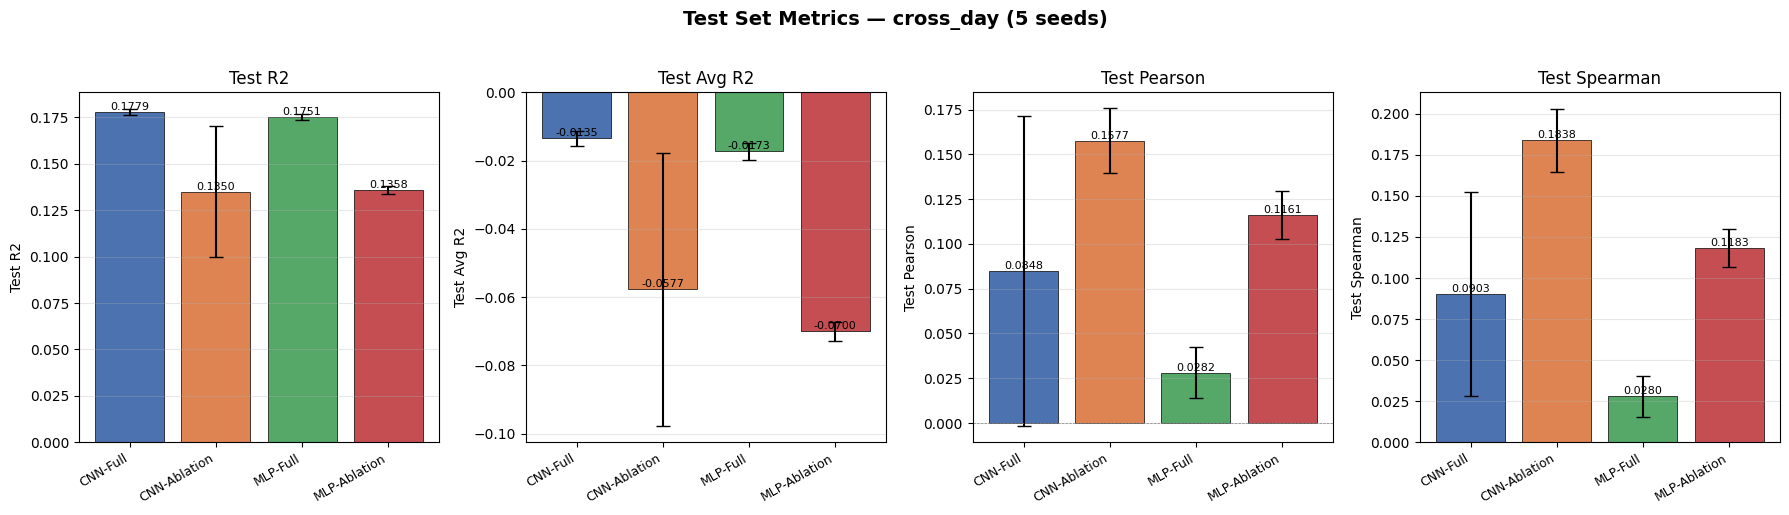

Saved: /root/zjm/cadt_test_code/ablation_comparison_bar_cross_day.png


In [21]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

plot_metrics = ['Test R2', 'Test Avg R2 (per-dim)', 'Test Pearson', 'Test Spearman']
plot_labels = ['Test R2', 'Test Avg R2', 'Test Pearson', 'Test Spearman']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, metric_key, label in zip(axes, plot_metrics, plot_labels):
    means, stds = [], []
    for exp_name in exp_names:
        vals = agg_values(all_data, exp_name, metric_key)
        means.append(np.mean(vals))
        stds.append(np.std(vals, ddof=1))

    bars = ax.bar(range(len(exp_names)), means, yerr=stds, capsize=5,
                  color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(label)
    ax.set_title(label, fontsize=12)
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.grid(axis='y', alpha=0.3)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{m:.4f}', ha='center', va='bottom', fontsize=8)

plt.suptitle(f'Test Set Metrics — {split_mode} (5 seeds)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
# [disabled: not referenced by md] plt.savefig(f'/root/zjm/cadt_test_code/ablation_comparison_bar_{split_mode}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: /root/zjm/cadt_test_code/ablation_comparison_bar_{split_mode}.png')

## 4. Per-Emotion Pearson 雷达图

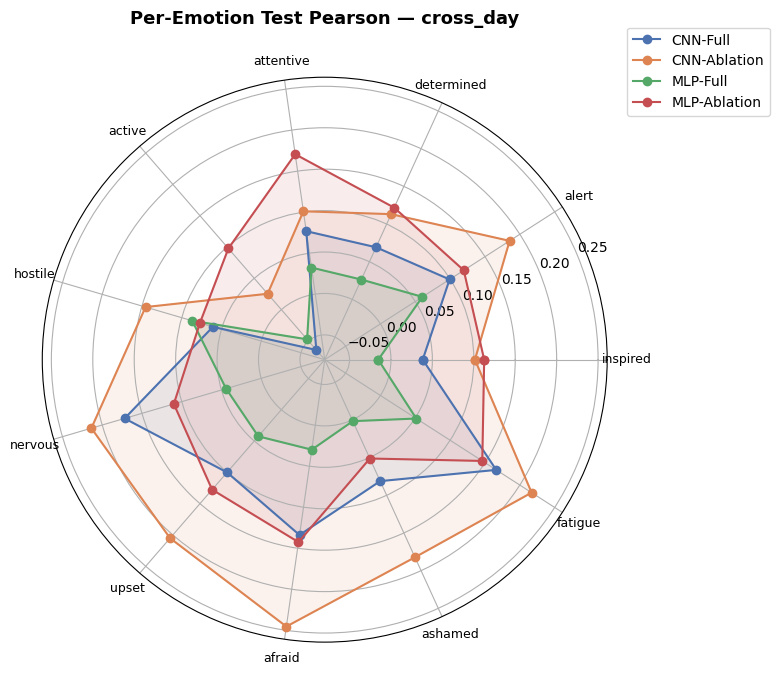

Saved: /root/zjm/cadt_test_code/ablation_radar_pearson_cross_day.png


In [22]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

angles = np.linspace(0, 2 * np.pi, len(EMOTIONS), endpoint=False).tolist()
angles += angles[:1]

for exp_name, color in zip(exp_names, colors):
    means = []
    for emo in EMOTIONS:
        vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric='Pearson')
        means.append(np.mean(vals))
    means += means[:1]
    ax.plot(angles, means, 'o-', linewidth=1.5, label=exp_name, color=color)
    ax.fill(angles, means, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(EMOTIONS, fontsize=9)
ax.set_title(f'Per-Emotion Test Pearson — {split_mode}', fontsize=13, fontweight='bold', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)
plt.tight_layout()
# [disabled: not referenced by md] plt.savefig(f'/root/zjm/cadt_test_code/ablation_radar_pearson_{split_mode}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: /root/zjm/cadt_test_code/ablation_radar_pearson_{split_mode}.png')

### Per-Emotion \u5206\u7ec4\u67f1\u72b6\u56fe (Pearson / Spearman / R2)\n
\u6bcf\u4e2a\u60c5\u7eea\u5c55\u793a 4 \u7ec4\u5b9e\u9a8c\u7684 mean\u00b1sd\uff085 seeds\uff09

In [23]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
import numpy as np

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

per_emo_metrics = [('Pearson', 'Test Pearson'), ('Spearman', 'Test Spearman'), ('R2', 'Test R2')]

for metric_name, _ in per_emo_metrics:
    fig, ax = plt.subplots(figsize=(16, 6))
    n_emotions = len(EMOTIONS)
    n_exp = len(exp_names)
    bar_width = 0.8 / n_exp
    x = np.arange(n_emotions)

    for i, exp_name in enumerate(exp_names):
        means, stds = [], []
        for emo in EMOTIONS:
            vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric_name)
            means.append(np.mean(vals))
            stds.append(np.std(vals, ddof=1))
        offset = (i - n_exp / 2 + 0.5) * bar_width
        bars = ax.bar(x + offset, means, bar_width, yerr=stds, capsize=3,
                      label=exp_name, color=colors[i], edgecolor='black', linewidth=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(EMOTIONS, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel(metric_name)
    ax.set_title(f'Per-Emotion Test {metric_name} \u2014 {split_mode} (mean\u00b1sd, 5 seeds)',
                 fontsize=14, fontweight='bold')
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    # [disabled: not referenced by md] plt.savefig(f'/root/zjm/cadt_test_code/per_emotion_{metric_name.lower()}_{split_mode}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: per_emotion_{metric_name.lower()}_{split_mode}.png')


IndentationError: unexpected indent (1641051202.py, line 38)

---
# cross_subject

## 1. 总体指标对比

In [ ]:
split_mode = 'cross_subject'
all_data = all_data_by_split[split_mode]

rows = []
for metric_key, display_name in OVERALL_METRICS:
    row = {'Metric': display_name}
    for exp_name in EXPERIMENTS:
        vals = agg_values(all_data, exp_name, metric_key)
        row[exp_name] = fmt_ms(vals)
    rows.append(row)

df_overall = pd.DataFrame(rows)
df_overall.style.set_caption(f'Overall Metrics — {split_mode} (mean±sd)').set_table_styles([
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold')]},
    {'selector': 'th', 'props': [('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]},
])

## 2. Per-Emotion Test 指标对比

In [ ]:
for metric in PER_EMOTION_METRICS:
    rows = []
    for emo in EMOTIONS + ['Average']:
        row = {'Emotion': emo}
        for exp_name in EXPERIMENTS:
            if emo == 'Average':
                vals = agg_values(all_data, exp_name, overall_key_map[metric])
            else:
                vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)

    df_emo = pd.DataFrame(rows).set_index('Emotion')
    display(df_emo.style
            .set_caption(f'Per-Emotion Test {metric} — {split_mode} (mean±sd)')
            .set_table_styles([
                {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold')]},
                {'selector': 'th', 'props': [('text-align', 'center')]},
                {'selector': 'td', 'props': [('text-align', 'center')]},
            ])
            .set_properties(**{'background-color': '#f9f9f9'}, subset=pd.IndexSlice['Average', :]))

## 3. 可视化对比

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, metric_key, label in zip(axes, plot_metrics, plot_labels):
    means, stds = [], []
    for exp_name in exp_names:
        vals = agg_values(all_data, exp_name, metric_key)
        means.append(np.mean(vals))
        stds.append(np.std(vals, ddof=1))

    bars = ax.bar(range(len(exp_names)), means, yerr=stds, capsize=5,
                  color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(label)
    ax.set_title(label, fontsize=12)
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.grid(axis='y', alpha=0.3)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{m:.4f}', ha='center', va='bottom', fontsize=8)

plt.suptitle(f'Test Set Metrics — {split_mode} (5 seeds)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
# [disabled: not referenced by md] plt.savefig(f'/root/zjm/cadt_test_code/ablation_comparison_bar_{split_mode}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: /root/zjm/cadt_test_code/ablation_comparison_bar_{split_mode}.png')

## 4. Per-Emotion Pearson 雷达图

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

angles = np.linspace(0, 2 * np.pi, len(EMOTIONS), endpoint=False).tolist()
angles += angles[:1]

for exp_name, color in zip(exp_names, colors):
    means = []
    for emo in EMOTIONS:
        vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric='Pearson')
        means.append(np.mean(vals))
    means += means[:1]
    ax.plot(angles, means, 'o-', linewidth=1.5, label=exp_name, color=color)
    ax.fill(angles, means, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(EMOTIONS, fontsize=9)
ax.set_title(f'Per-Emotion Test Pearson — {split_mode}', fontsize=13, fontweight='bold', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)
plt.tight_layout()
# [disabled: not referenced by md] plt.savefig(f'/root/zjm/cadt_test_code/ablation_radar_pearson_{split_mode}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: /root/zjm/cadt_test_code/ablation_radar_pearson_{split_mode}.png')

### Per-Emotion \u5206\u7ec4\u67f1\u72b6\u56fe (Pearson / Spearman / R2)\n
\u6bcf\u4e2a\u60c5\u7eea\u5c55\u793a 4 \u7ec4\u5b9e\u9a8c\u7684 mean\u00b1sd\uff085 seeds\uff09

In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
import numpy as np

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

per_emo_metrics = [('Pearson', 'Test Pearson'), ('Spearman', 'Test Spearman'), ('R2', 'Test R2')]

for metric_name, _ in per_emo_metrics:
    fig, ax = plt.subplots(figsize=(16, 6))
    n_emotions = len(EMOTIONS)
    n_exp = len(exp_names)
    bar_width = 0.8 / n_exp
    x = np.arange(n_emotions)

    for i, exp_name in enumerate(exp_names):
        means, stds = [], []
        for emo in EMOTIONS:
            vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric_name)
            means.append(np.mean(vals))
            stds.append(np.std(vals, ddof=1))
        offset = (i - n_exp / 2 + 0.5) * bar_width
        bars = ax.bar(x + offset, means, bar_width, yerr=stds, capsize=3,
                      label=exp_name, color=colors[i], edgecolor='black', linewidth=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(EMOTIONS, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel(metric_name)
    ax.set_title(f'Per-Emotion Test {metric_name} \u2014 {split_mode} (mean\u00b1sd, 5 seeds)',
                 fontsize=14, fontweight='bold')
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    # [disabled: not referenced by md] plt.savefig(f'/root/zjm/cadt_test_code/per_emotion_{metric_name.lower()}_{split_mode}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: per_emotion_{metric_name.lower()}_{split_mode}.png')


---
# 5. 两种 split mode 并排对比

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for row_idx, split_mode in enumerate(SPLIT_MODES):
    all_data = all_data_by_split[split_mode]
    for col_idx, (metric_key, label) in enumerate(zip(plot_metrics, plot_labels)):
        ax = axes[row_idx][col_idx]
        means, stds = [], []
        for exp_name in exp_names:
            vals = agg_values(all_data, exp_name, metric_key)
            means.append(np.mean(vals))
            stds.append(np.std(vals, ddof=1))

        bars = ax.bar(range(len(exp_names)), means, yerr=stds, capsize=5,
                      color=colors, edgecolor='black', linewidth=0.5)
        ax.set_xticks(range(len(exp_names)))
        ax.set_xticklabels(exp_names, rotation=30, ha='right', fontsize=8)
        ax.set_ylabel(label)
        ax.set_title(f'{label} ({split_mode})', fontsize=11)
        ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
        ax.grid(axis='y', alpha=0.3)
        for bar, m in zip(bars, means):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f'{m:.4f}', ha='center', va='bottom', fontsize=7)

plt.suptitle('Cross-Split Comparison (5 seeds)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
# [disabled: not referenced by md] plt.savefig('/root/zjm/cadt_test_code/ablation_comparison_cross_split.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: /root/zjm/cadt_test_code/ablation_comparison_cross_split.png')

## 6. 导出 CSV

In [ ]:
output_dir = '/root/zjm/cadt_test_code'

for split_mode in SPLIT_MODES:
    all_data = all_data_by_split[split_mode]

    # overall
    rows = []
    for metric_key, display_name in OVERALL_METRICS:
        row = {'Metric': display_name}
        for exp_name in EXPERIMENTS:
            vals = agg_values(all_data, exp_name, metric_key)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)
    # [disabled: not referenced by md] pd.DataFrame(rows).to_csv(os.path.join(output_dir, f'compare_ablation_overall_{split_mode}.csv'), index=False)
    print(f'Saved: compare_ablation_overall_{split_mode}.csv')

    # per-emotion
    for metric in PER_EMOTION_METRICS:
        rows = []
        for emo in EMOTIONS + ['Average']:
            row = {'Emotion': emo}
            for exp_name in EXPERIMENTS:
                if emo == 'Average':
                    vals = agg_values(all_data, exp_name, overall_key_map[metric])
                else:
                    vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
                row[exp_name] = fmt_ms(vals)
            rows.append(row)
        # [disabled: not referenced by md] pd.DataFrame(rows).to_csv(os.path.join(output_dir, f'compare_ablation_test_{metric}_{split_mode}.csv'), index=False)
        print(f'Saved: compare_ablation_test_{metric}_{split_mode}.csv')

print('Done!')